# Evaluation — forecast so với thực tế, MAE/WIS và coverage

Chạy các cell theo thứ tự bằng kernel **`.venv`**. Evaluation đọc issued predictions
rồi ghép **raw final COVID truth**, không sinh lại dữ liệu hay chạy lại BO.

Mặc định `EVALUATION_MODE="saved"` hiển thị kết quả job full đã lưu.
Chọn `"recompute"` để tính lại bằng cùng evaluator trên predictions đã hoàn tất;
artifact mới nằm ở `outputs/notebook_evaluation/full`. Forecasting thực hiện trong
`forecasting.ipynb`. Cả MAE và WIS càng thấp càng tốt.

**Lưu ý phiên bản:** artifacts `outputs/reproduction_full` đang hiển thị là
run legacy **final truth + spline**. Code mới mặc định dùng thin plate GAM/GCV.
Xem [Experiment 0](../reproduction/experiment_0.ipynb) để đọc kết quả đã chạy
lại với historical JHU và forecast COVIDHub gốc; không đồng nhất hai run.


In [1]:
from pathlib import Path
from datetime import datetime, timezone
from io import BytesIO
import json
import os
import subprocess
import sys
import tempfile

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents]
            if (p / "experiments/run_pipeline.py").is_file())
for folder in ["experiments", "experiments/forecasting"]:
    sys.path.insert(0, str(ROOT / folder))
os.environ.setdefault("MPLCONFIGDIR", str(Path(tempfile.gettempdir()) / "smoa-notebook-matplotlib"))
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display, Image, Markdown

pd.set_option("display.max_columns", 15)
pd.set_option("display.float_format", lambda value: f"{value:,.2f}")

def read_json(path):
    return json.loads(Path(path).read_text()) if Path(path).is_file() else {}

def show_figure(fig):
    buffer = BytesIO()
    fig.savefig(buffer, format="png", dpi=140, bbox_inches="tight", facecolor="white")
    plt.close(fig)
    display(Image(data=buffer.getvalue()))

print("Python:", sys.executable)
print("Snapshot UTC:", datetime.now(timezone.utc).isoformat())

Python: /Users/nguyentranglinh/infectious-disease-forecasting/.venv/bin/python
Snapshot UTC: 2026-10-29T15:43:03.278359+00:00


## 1. Nguồn dữ liệu và lựa chọn bang

`SELECTED_SERIES` chỉ chọn báo cáo/hình để hiển thị. Khi chấm benchmark,
score gộp vẫn dùng mọi bang trong manifest, có trọng số theo số issued forecasts.

In [2]:
RUN_DIR = ROOT / "outputs/reproduction_full"
MANIFEST = ROOT / "outputs/truth_states/manifest.csv"
PREDICTION_DIR = RUN_DIR / "04_prediction"
SELECTED_SERIES = "California"
EVALUATION_MODE = "saved"  # "saved": đọc báo cáo có sẵn; "recompute": tính lại từ predictions
NOTEBOOK_EVALUATION_DIR = ROOT / "outputs/notebook_evaluation/full"
REFERENCE_SCORES = None  # Path tới canonical external-model scores nếu đã chuẩn bị

## 2. Kiểm tra trạng thái prediction

Chỉ tổng hợp 50 bang khi benchmark đã hoàn tất. Nếu job còn ở BO/prediction,
notebook hiển thị pending và không tạo bảng điểm giả hoặc coi benchmark một phần là full.

In [3]:
if EVALUATION_MODE not in {"saved", "recompute"}:
    raise ValueError("EVALUATION_MODE phải là saved hoặc recompute")
manifest = pd.read_csv(MANIFEST, keep_default_na=False)
selected_entry = manifest.loc[manifest["series"] == SELECTED_SERIES]
if len(selected_entry) != 1:
    raise ValueError(f"Không tìm thấy đúng một bang {SELECTED_SERIES}")
TRUTH = (MANIFEST.parent / selected_entry.iloc[0]["truth"]).resolve()
prediction_metadata = read_json(PREDICTION_DIR / "metadata.json")
IS_BENCHMARK = (PREDICTION_DIR / "series_metrics.csv").is_file()
PREDICTION_READY = (prediction_metadata.get("status") == "complete" if IS_BENCHMARK else
                    bool(prediction_metadata) and (PREDICTION_DIR / "predictions.csv").is_file())
display(pd.DataFrame([{
    "pipeline status": read_json(RUN_DIR / "pipeline.json").get("status", "not started"),
    "prediction ready": PREDICTION_READY,
    "manifest states": len(manifest),
    "prediction source": str(PREDICTION_DIR.relative_to(ROOT)) if PREDICTION_DIR.is_relative_to(ROOT) else str(PREDICTION_DIR),
}]))
if not PREDICTION_READY:
    print("Prediction chưa hoàn tất. Chưa chấm điểm full; chạy lại notebook khi có artifact hoàn chỉnh.")

,pipeline status,prediction ready,manifest states,prediction source
0,complete,True,50,outputs/reproduction_full/04_prediction


## 3. Chấm điểm hoặc đọc evaluation đã lưu

WIS = `2 * mean(pinball loss)` tại 7 quantiles `[.025,.1,.25,.5,.75,.9,.975]`
như helper nguồn. Coverage dùng 23 quantiles → 11 central intervals.
Giữ nguyên zero/negative truth để chấm; không floor actual về 1.

In [4]:
from evaluate import evaluate_outputs, evaluate_benchmark
from evaluation_report import format_metrics

EVALUATION_DIR = RUN_DIR / "05_evaluation" if EVALUATION_MODE == "saved" else NOTEBOOK_EVALUATION_DIR
if EVALUATION_MODE == "recompute" and PREDICTION_READY:
    if IS_BENCHMARK:
        evaluate_benchmark(PREDICTION_DIR, MANIFEST, EVALUATION_DIR)
    else:
        evaluate_outputs(PREDICTION_DIR, TRUTH, EVALUATION_DIR)
elif EVALUATION_MODE == "recompute":
    print("Đang chờ issued predictions đầy đủ; chưa gọi evaluator.")

summary = read_json(EVALUATION_DIR / "summary.json")
if summary:
    print(format_metrics(summary))
    print("Report:", EVALUATION_DIR / "report.md")
else:
    print("Chưa có summary evaluation ở", EVALUATION_DIR)

Evaluation: 22468 forecasts/model; raw final truth
Model                      MAE            WIS
sMOA                  7,564.27       4,765.92
Persistence           8,385.71       5,242.59
Report: /Users/nguyentranglinh/infectious-disease-forecasting/outputs/reproduction_full/05_evaluation/report.md


## 4. MAE/WIS tổng hợp và theo horizon

MAE là sai số tuyệt đối trung bình của dự báo điểm. WIS chấm phân phối dự báo,
cân bằng độ rộng khoảng và phần phạt khi actual nằm ngoài khoảng.
Điểm pooled lấy trung bình trên origin–horizon; một tuần target có thể xuất hiện
ở nhiều horizon. Persistence giữ giá trị quan sát cuối cùng tại mỗi origin.

In [5]:
overall_table = horizon_table = None
if summary:
    overall_table = pd.DataFrame(summary["models"]).T
    overall_table.index.name = "model"
    columns = [c for c in ["mae", "wis", "coverage_50", "coverage_80", "coverage_95"] if c in overall_table]
    display(overall_table[columns].rename(columns={"mae":"MAE", "wis":"WIS"}))
    print(f"Số forecasts/model: {summary['forecasts_per_model']:,}")
    horizon_rows = [dict(horizon=int(horizon), model=model, **metrics)
                    for horizon, models in summary["by_horizon"].items() for model, metrics in models.items()]
    horizon_table = pd.DataFrame(horizon_rows).sort_values(["horizon", "model"])
    display(horizon_table.rename(columns={"mae":"MAE", "wis":"WIS"}))
    if (EVALUATION_DIR / "series_metrics.csv").is_file():
        display(pd.read_csv(EVALUATION_DIR / "series_metrics.csv").head(12))
else:
    print("MAE/WIS sẽ xuất hiện sau khi evaluation hoàn tất; hiện chưa có giá trị để báo cáo.")

,MAE,WIS,coverage_50,coverage_80,coverage_95
model,,,,,
smoa,"7,564.27","4,765.92",0.55,0.77,0.87
persistence,"8,385.71","5,242.59",0.54,0.79,0.90


Số forecasts/model: 22,468


,horizon,model,n,MAE,WIS
1,1,persistence,5617,"4,485.58","2,750.43"
0,1,smoa,5617,"3,954.88","2,438.67"
3,2,persistence,5617,"7,111.17","4,348.60"
2,2,smoa,5617,"6,266.74","3,926.05"
5,3,persistence,5617,"10,009.04","6,246.69"
4,3,smoa,5617,"9,141.04","5,740.71"
7,4,persistence,5617,"11,937.06","7,624.64"
6,4,smoa,5617,"10,894.43","6,958.26"


,series,model,n,mae,wis,report
0,Alabama,smoa,448,"7,506.47","4,912.65",01/report.md
1,Alabama,persistence,448,"7,404.96","4,677.50",01/report.md
2,Alaska,smoa,448,"1,138.58",795.28,02/report.md
3,Alaska,persistence,448,"1,266.62",792.78,02/report.md
4,Arizona,smoa,516,"8,597.72","5,465.06",03/report.md
5,Arizona,persistence,516,"8,787.70","5,253.63",03/report.md
6,Arkansas,smoa,448,"3,348.58","2,236.87",04/report.md
7,Arkansas,persistence,448,"4,107.60","2,577.05",04/report.md
8,California,smoa,448,"45,277.36","28,000.18",05/report.md
9,California,persistence,448,"55,089.95","35,211.55",05/report.md


## 5. Báo cáo chi tiết theo bang

Chọn output subdir bằng tên bang trong index, không hard-code California = `05`.
Bảng dưới lấy đúng `scores.csv` đã được evaluator chấm từ raw actuals.

In [6]:
STATE_EVALUATION_DIR = STATE_PREDICTION_DIR = None
state_index_path = PREDICTION_DIR / "series_metrics.csv"
if state_index_path.is_file():
    state_index = pd.read_csv(state_index_path, dtype={"output_subdir":str})
    found = state_index.loc[state_index["series"] == SELECTED_SERIES]
    if len(found) == 1:
        subdir = found.iloc[0]["output_subdir"]
        STATE_PREDICTION_DIR = PREDICTION_DIR / subdir
        STATE_EVALUATION_DIR = EVALUATION_DIR / subdir
elif (PREDICTION_DIR / "predictions.csv").is_file():
    first = pd.read_csv(PREDICTION_DIR / "predictions.csv", nrows=1)
    if first.iloc[0]["series"] == SELECTED_SERIES:
        STATE_PREDICTION_DIR = PREDICTION_DIR
        STATE_EVALUATION_DIR = EVALUATION_DIR

state_summary = read_json(STATE_EVALUATION_DIR / "summary.json") if STATE_EVALUATION_DIR else {}
if state_summary:
    print(SELECTED_SERIES)
    print(format_metrics(state_summary))
    state_scores = pd.read_csv(STATE_EVALUATION_DIR / "scores.csv")
    display(state_scores.head(12))
else:
    print(f"Chưa có evaluation của {SELECTED_SERIES}.")

California
Evaluation: 448 forecasts/model; raw final truth
Model                      MAE            WIS
sMOA                 45,277.36      28,000.18
Persistence          55,089.95      35,211.55


,series,forecast_origin,target_end_date,horizon,model,forecast,true_value,...,overprediction,underprediction,sharpness,coverage_50,coverage_80,coverage_95,width_95
0,California,2020-08-15,2020-08-22,1,smoa,"59,681.00","41,872.00",...,"3,838.00",0.00,"4,139.85",0,1,1,"82,752.22"
1,California,2020-08-15,2020-08-22,1,persistence,"65,500.00","41,872.00",...,"3,600.29",0.00,"8,102.58",0,1,1,"169,542.72"
2,California,2020-08-15,2020-08-29,2,smoa,"59,096.00","36,279.00",...,"4,689.71",0.00,"5,980.17",0,1,1,"120,637.17"
3,California,2020-08-15,2020-08-29,2,persistence,"65,500.00","36,279.00",...,"4,887.00",0.00,"10,898.22",0,1,1,"232,600.00"
4,California,2020-08-15,2020-09-05,3,smoa,"58,364.00","32,449.00",...,"6,738.21",0.00,"5,163.33",0,1,1,"102,748.02"
5,California,2020-08-15,2020-09-05,3,persistence,"65,500.00","32,449.00",...,"6,487.36",0.00,"10,891.86",0,1,1,"237,865.37"
6,California,2020-08-15,2020-09-12,4,smoa,"57,778.00","23,024.00",...,"10,349.09",0.00,"6,423.49",0,0,1,"130,908.65"
7,California,2020-08-15,2020-09-12,4,persistence,"65,500.00","23,024.00",...,"11,977.26",0.00,"10,609.36",0,0,1,"234,962.92"
8,California,2020-08-22,2020-08-29,1,smoa,"39,050.00","36,279.00",...,395.86,0.00,"2,623.35",1,1,1,"52,139.72"
9,California,2020-08-22,2020-08-29,1,persistence,"41,872.00","36,279.00",...,799.00,0.00,"5,007.62",1,1,1,"104,747.62"


## 6. Diagram: dự báo so với thực tế

Đen: actual raw. Xanh: sMOA. Cam nét đứt: persistence. Vùng xanh: predictive
intervals 50% và 95%. Mỗi panel giữ một horizon cố định; các điểm nối tiếp thuộc
những origin khác nhau. Hình thứ hai đối chiếu MAE/WIS theo horizon.

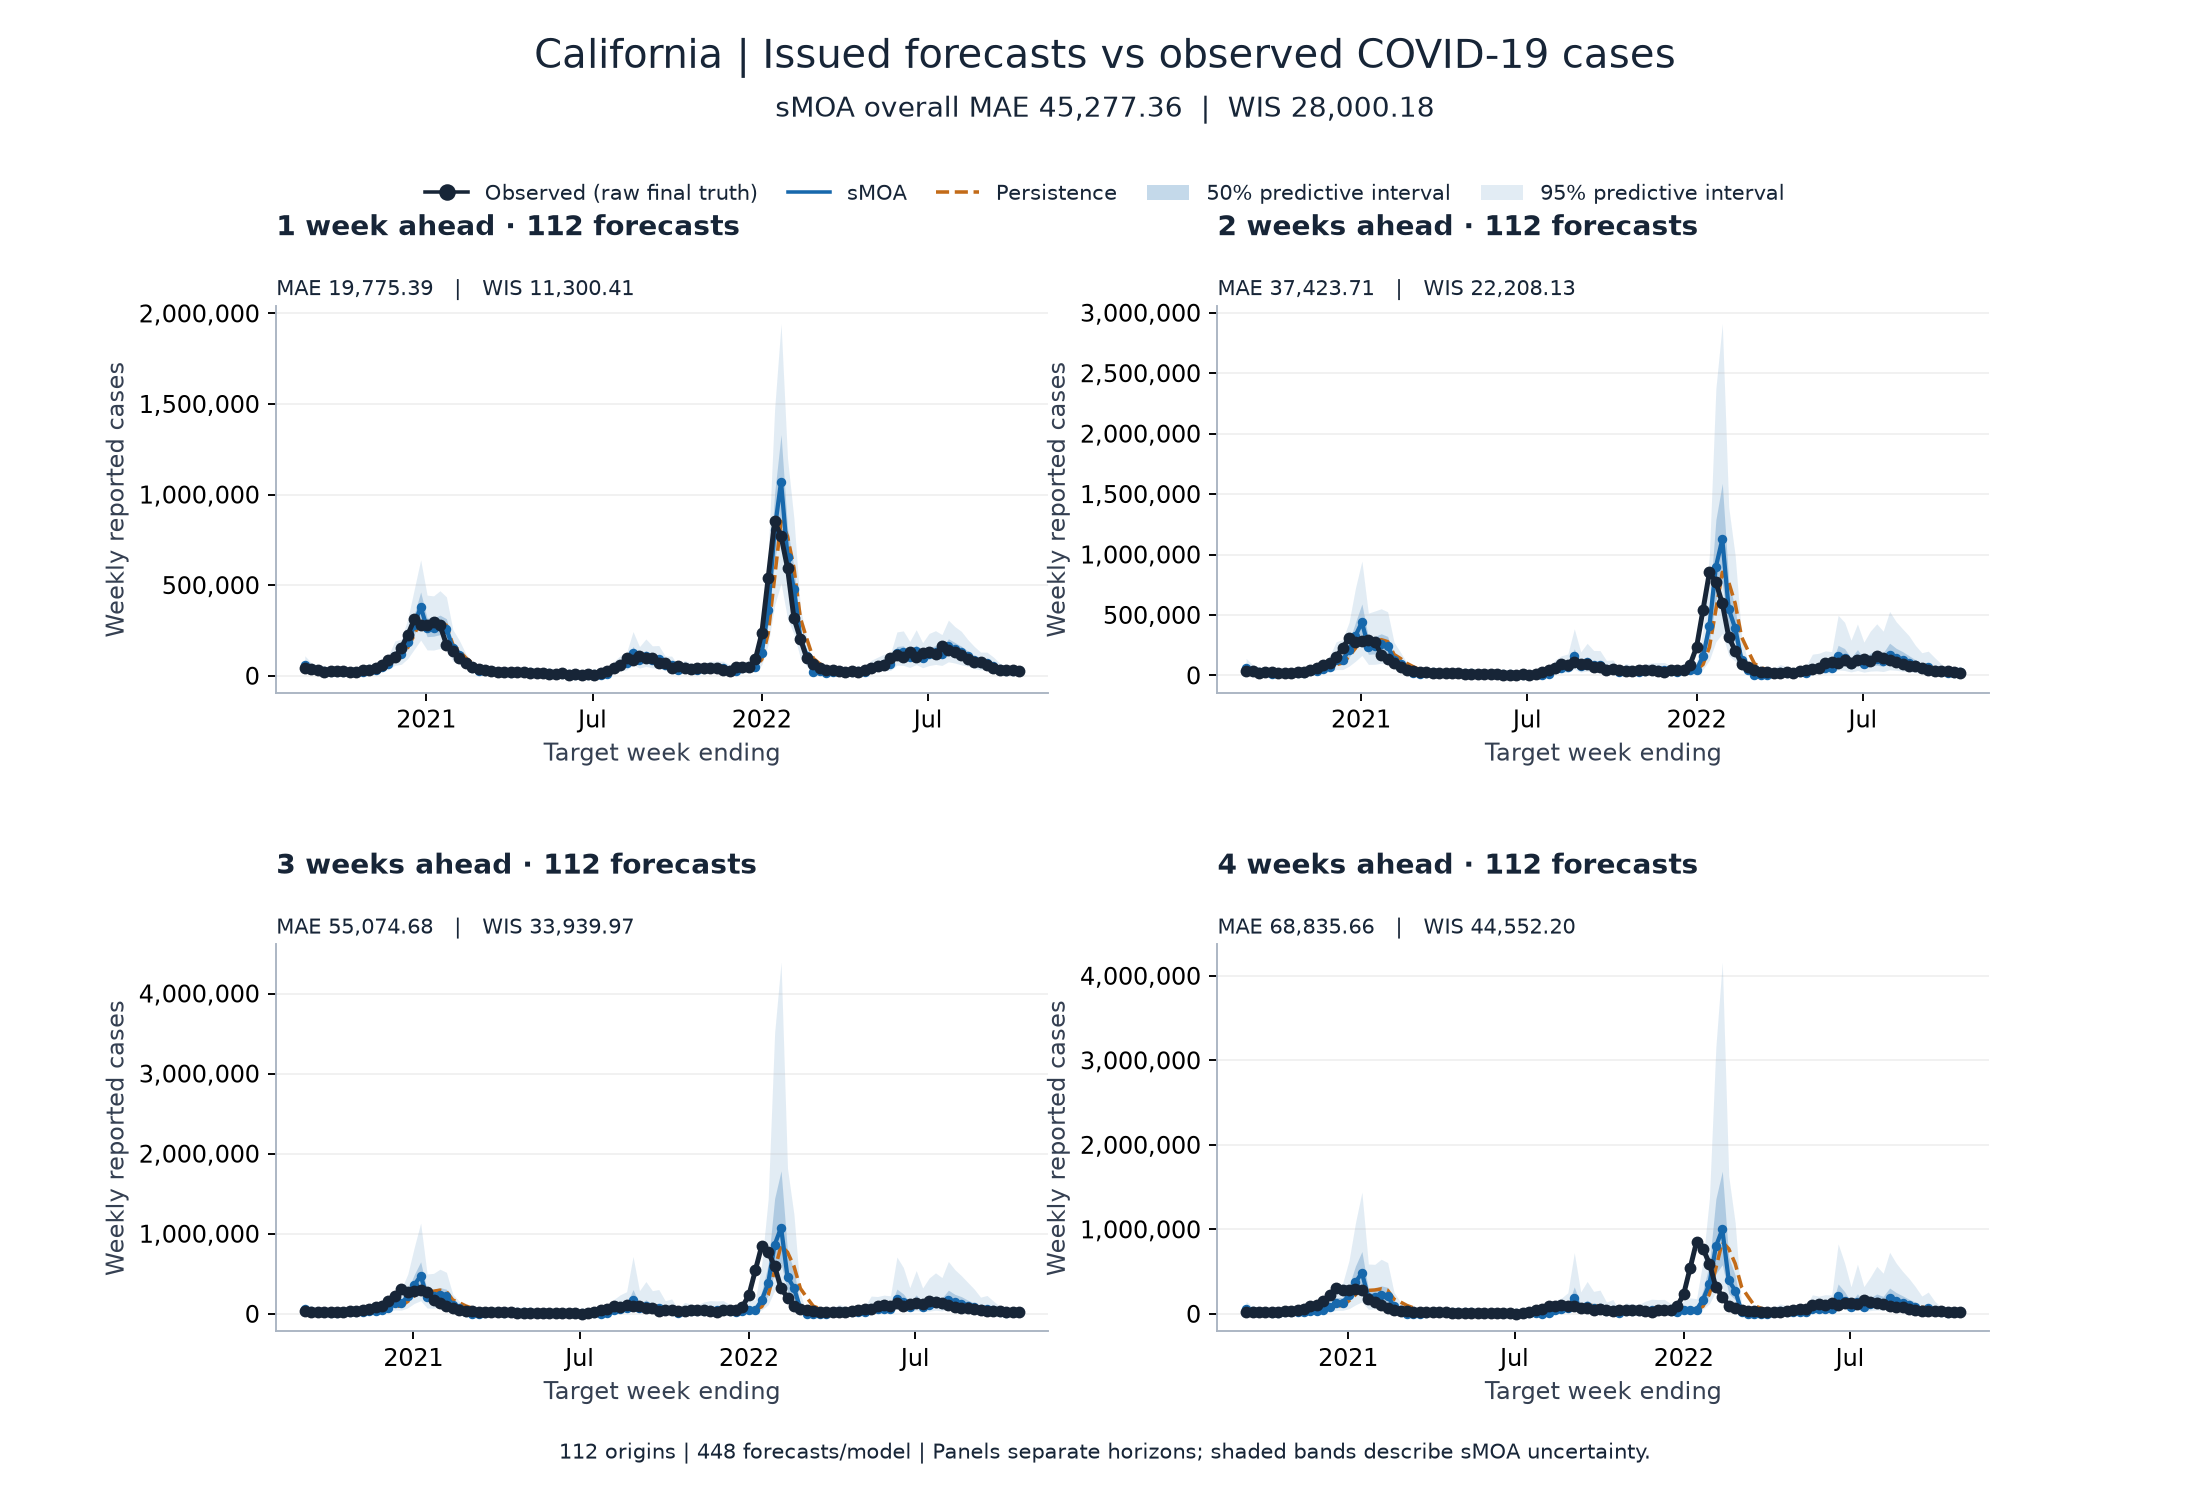

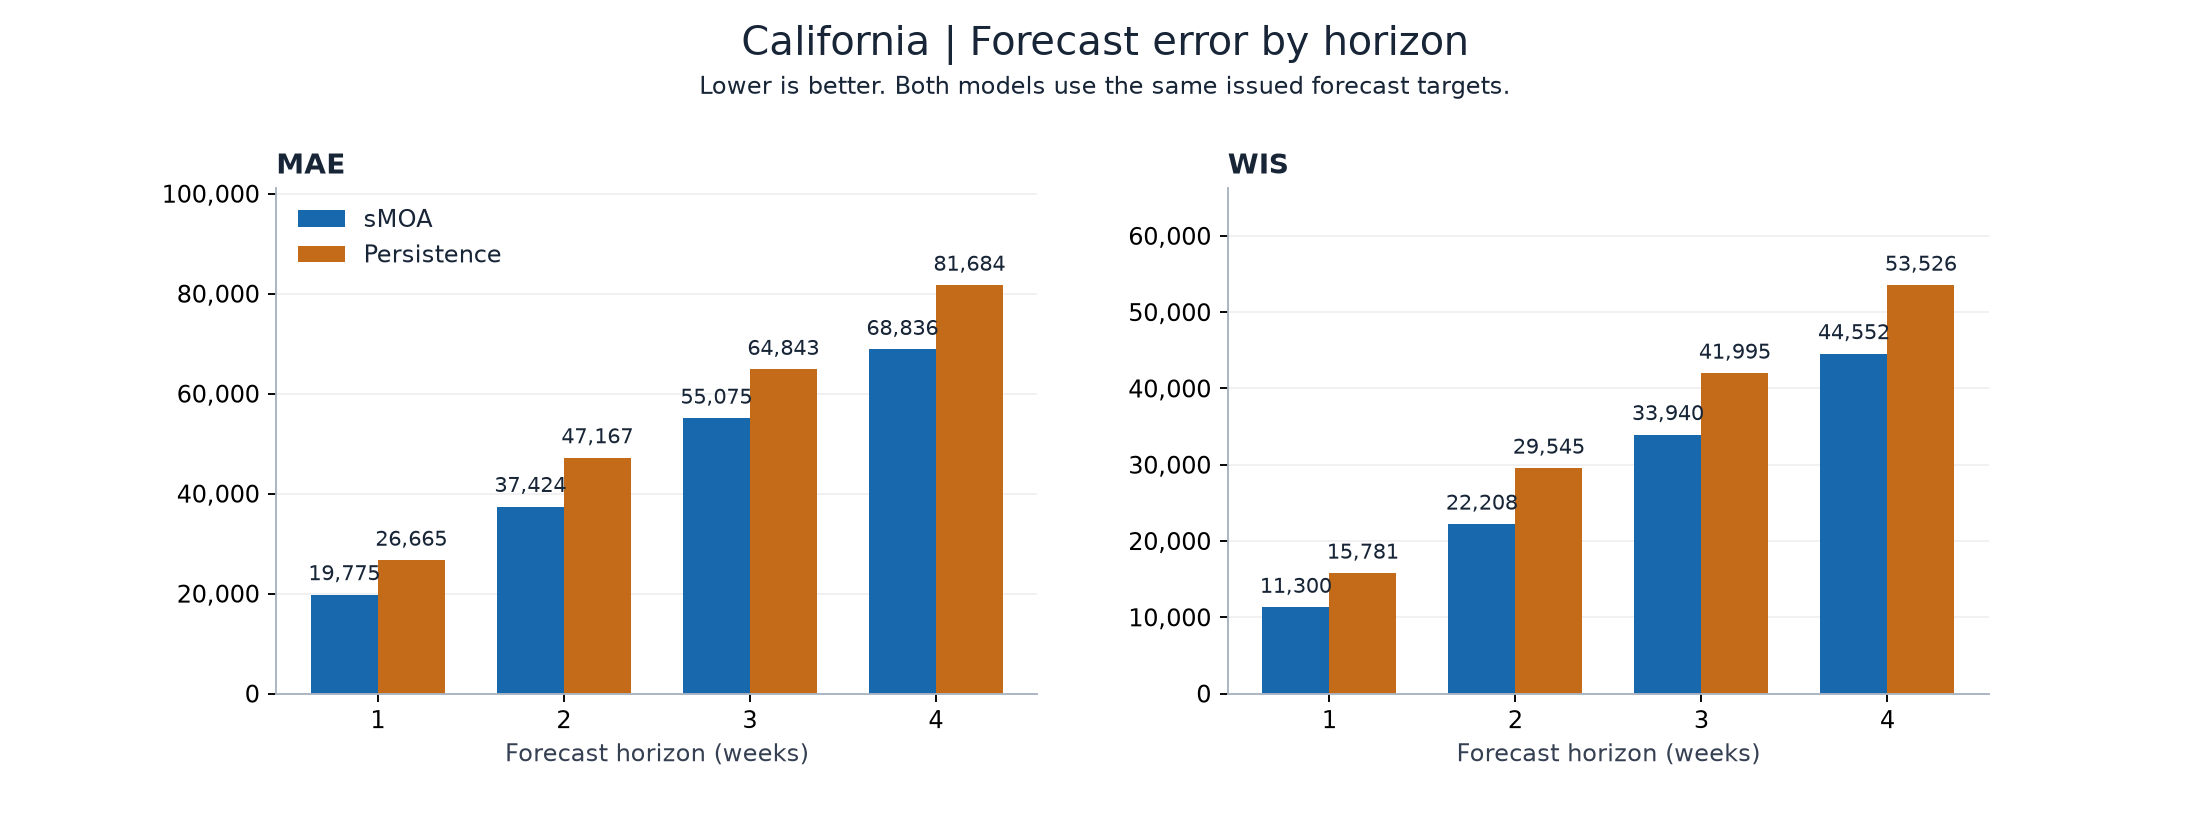

In [7]:
if STATE_EVALUATION_DIR is not None:
    for name in ["forecast_vs_actual.png", "metrics_by_horizon.png"]:
        path = STATE_EVALUATION_DIR / name
        if path.is_file():
            display(Image(filename=str(path)))
        else:
            print("Chưa có hình:", name)
else:
    print("Chưa có forecast/actual diagram để hiển thị.")

## 7. Calibration: coverage quan sát so với nominal coverage

Đường chéo là tỷ lệ bao phủ danh nghĩa. Điểm thấp hơn đường chéo nghĩa là
interval bao phủ ít hơn mức danh nghĩa trên tập forecast đang chấm.
Nguồn dùng điều kiện `lower < actual <= upper`.

,model,level,observed_coverage,forecasts
0,persistence,0.10,0.16,448
1,persistence,0.20,0.25,448
2,persistence,0.30,0.37,448
3,persistence,0.40,0.48,448
4,persistence,0.50,0.58,448
5,persistence,0.60,0.69,448
6,persistence,0.70,0.78,448
7,persistence,0.80,0.84,448
8,persistence,0.90,0.89,448
9,persistence,0.95,0.92,448


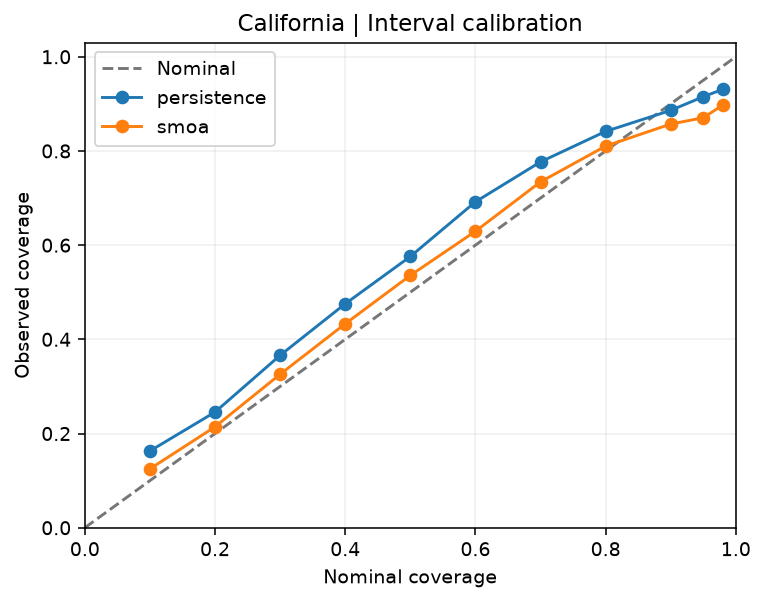

In [8]:
coverage_path = STATE_EVALUATION_DIR / "coverage.csv" if STATE_EVALUATION_DIR else None
if coverage_path is not None and coverage_path.is_file():
    coverage = pd.read_csv(coverage_path)
    calibration_table = coverage.groupby(["model", "level"], as_index=False).agg(
        observed_coverage=("covered", "mean"), forecasts=("covered", "size"))
    display(calibration_table)
    fig, ax = plt.subplots(figsize=(6, 4.5))
    ax.plot([0,1], [0,1], color="#777777", linestyle="--", label="Nominal")
    for model, group in calibration_table.groupby("model"):
        group = group.sort_values("level")
        ax.plot(group["level"], group["observed_coverage"], marker="o", label=model)
    ax.set(title=f"{SELECTED_SERIES} | Interval calibration", xlabel="Nominal coverage",
           ylabel="Observed coverage", xlim=(0,1), ylim=(0,1.03))
    ax.legend(); ax.grid(alpha=.2)
    show_figure(fig)
else:
    calibration_table = None
    print("Chưa có coverage.csv. Point-only predictions không có coverage/WIS.")

## 8. External model comparison khi đã có score archive

Giữ nguyên phép so sánh trên các targets chung. Không so hai mean trên hai
sample khác nhau. Để trống `REFERENCE_SCORES` khi chưa có archive thật.

In [9]:
if REFERENCE_SCORES is not None and summary:
    from compare_models import compare
    paired_rows = compare(EVALUATION_DIR / "scores.csv", Path(REFERENCE_SCORES), EVALUATION_DIR / "reference_comparison")
    display(pd.DataFrame(paired_rows))
else:
    print("Chưa thực hiện external-model comparison; cần canonical score archive thật.")

Chưa thực hiện external-model comparison; cần canonical score archive thật.


## Cách đọc kết quả

Full ngân sách BO và full số bang không chứng minh khớp metric công bố.
Kiểm tra protocol `as_of`/`final`, UQ calibration và selected bank trong metadata.
Không dùng score trên COVID để tune lại rồi báo score đó như test độc lập.
Artifacts CSV/report/PNG/SVG vẫn được xuất để tái lập và chia sẻ ngoài notebook.